# Walkthrough: overlapping feature selection for LUAD vs LUSC

This notebook is a guided tour of the results. It reads the tables and figures already committed in `results/`, so it runs in seconds and needs no data download. To regenerate everything from raw TCGA data, run `bash download_data.sh && make reproduce` from the repository root.

**The question.** Lung adenocarcinoma (LUAD) and lung squamous cell carcinoma (LUSC) are the two main non-small-cell lung cancers. Can a small, trustworthy gene panel tell them apart from bulk RNA-seq, and which genes carry the signal?

**The approach** reproduces Chen & Dhahbi, *Sci Rep* 2021 ([DOI 10.1038/s41598-021-92725-8](https://doi.org/10.1038/s41598-021-92725-8)). Five feature selectors that fail in different ways each pick genes, and the genes they agree on become the panel.

**Cohort.** 528 LUAD and 501 LUSC primary tumours plus 110 normals from TCGA, with 15,686 genes after filtering. The external validation cohort is GSE28582 (78 tumours, Affymetrix microarray).

## Interpreting the saved results
This notebook presents a saved educational analysis. See [VALIDATION.md](../docs/VALIDATION.md) and the [research guide](../docs/pdf/PROJECT_GUIDE.pdf) for current limitations. Binary panel differences are small, external AUCs describe single genes, and three-class and survival results are exploratory. The full multigene classifier has not been externally validated.


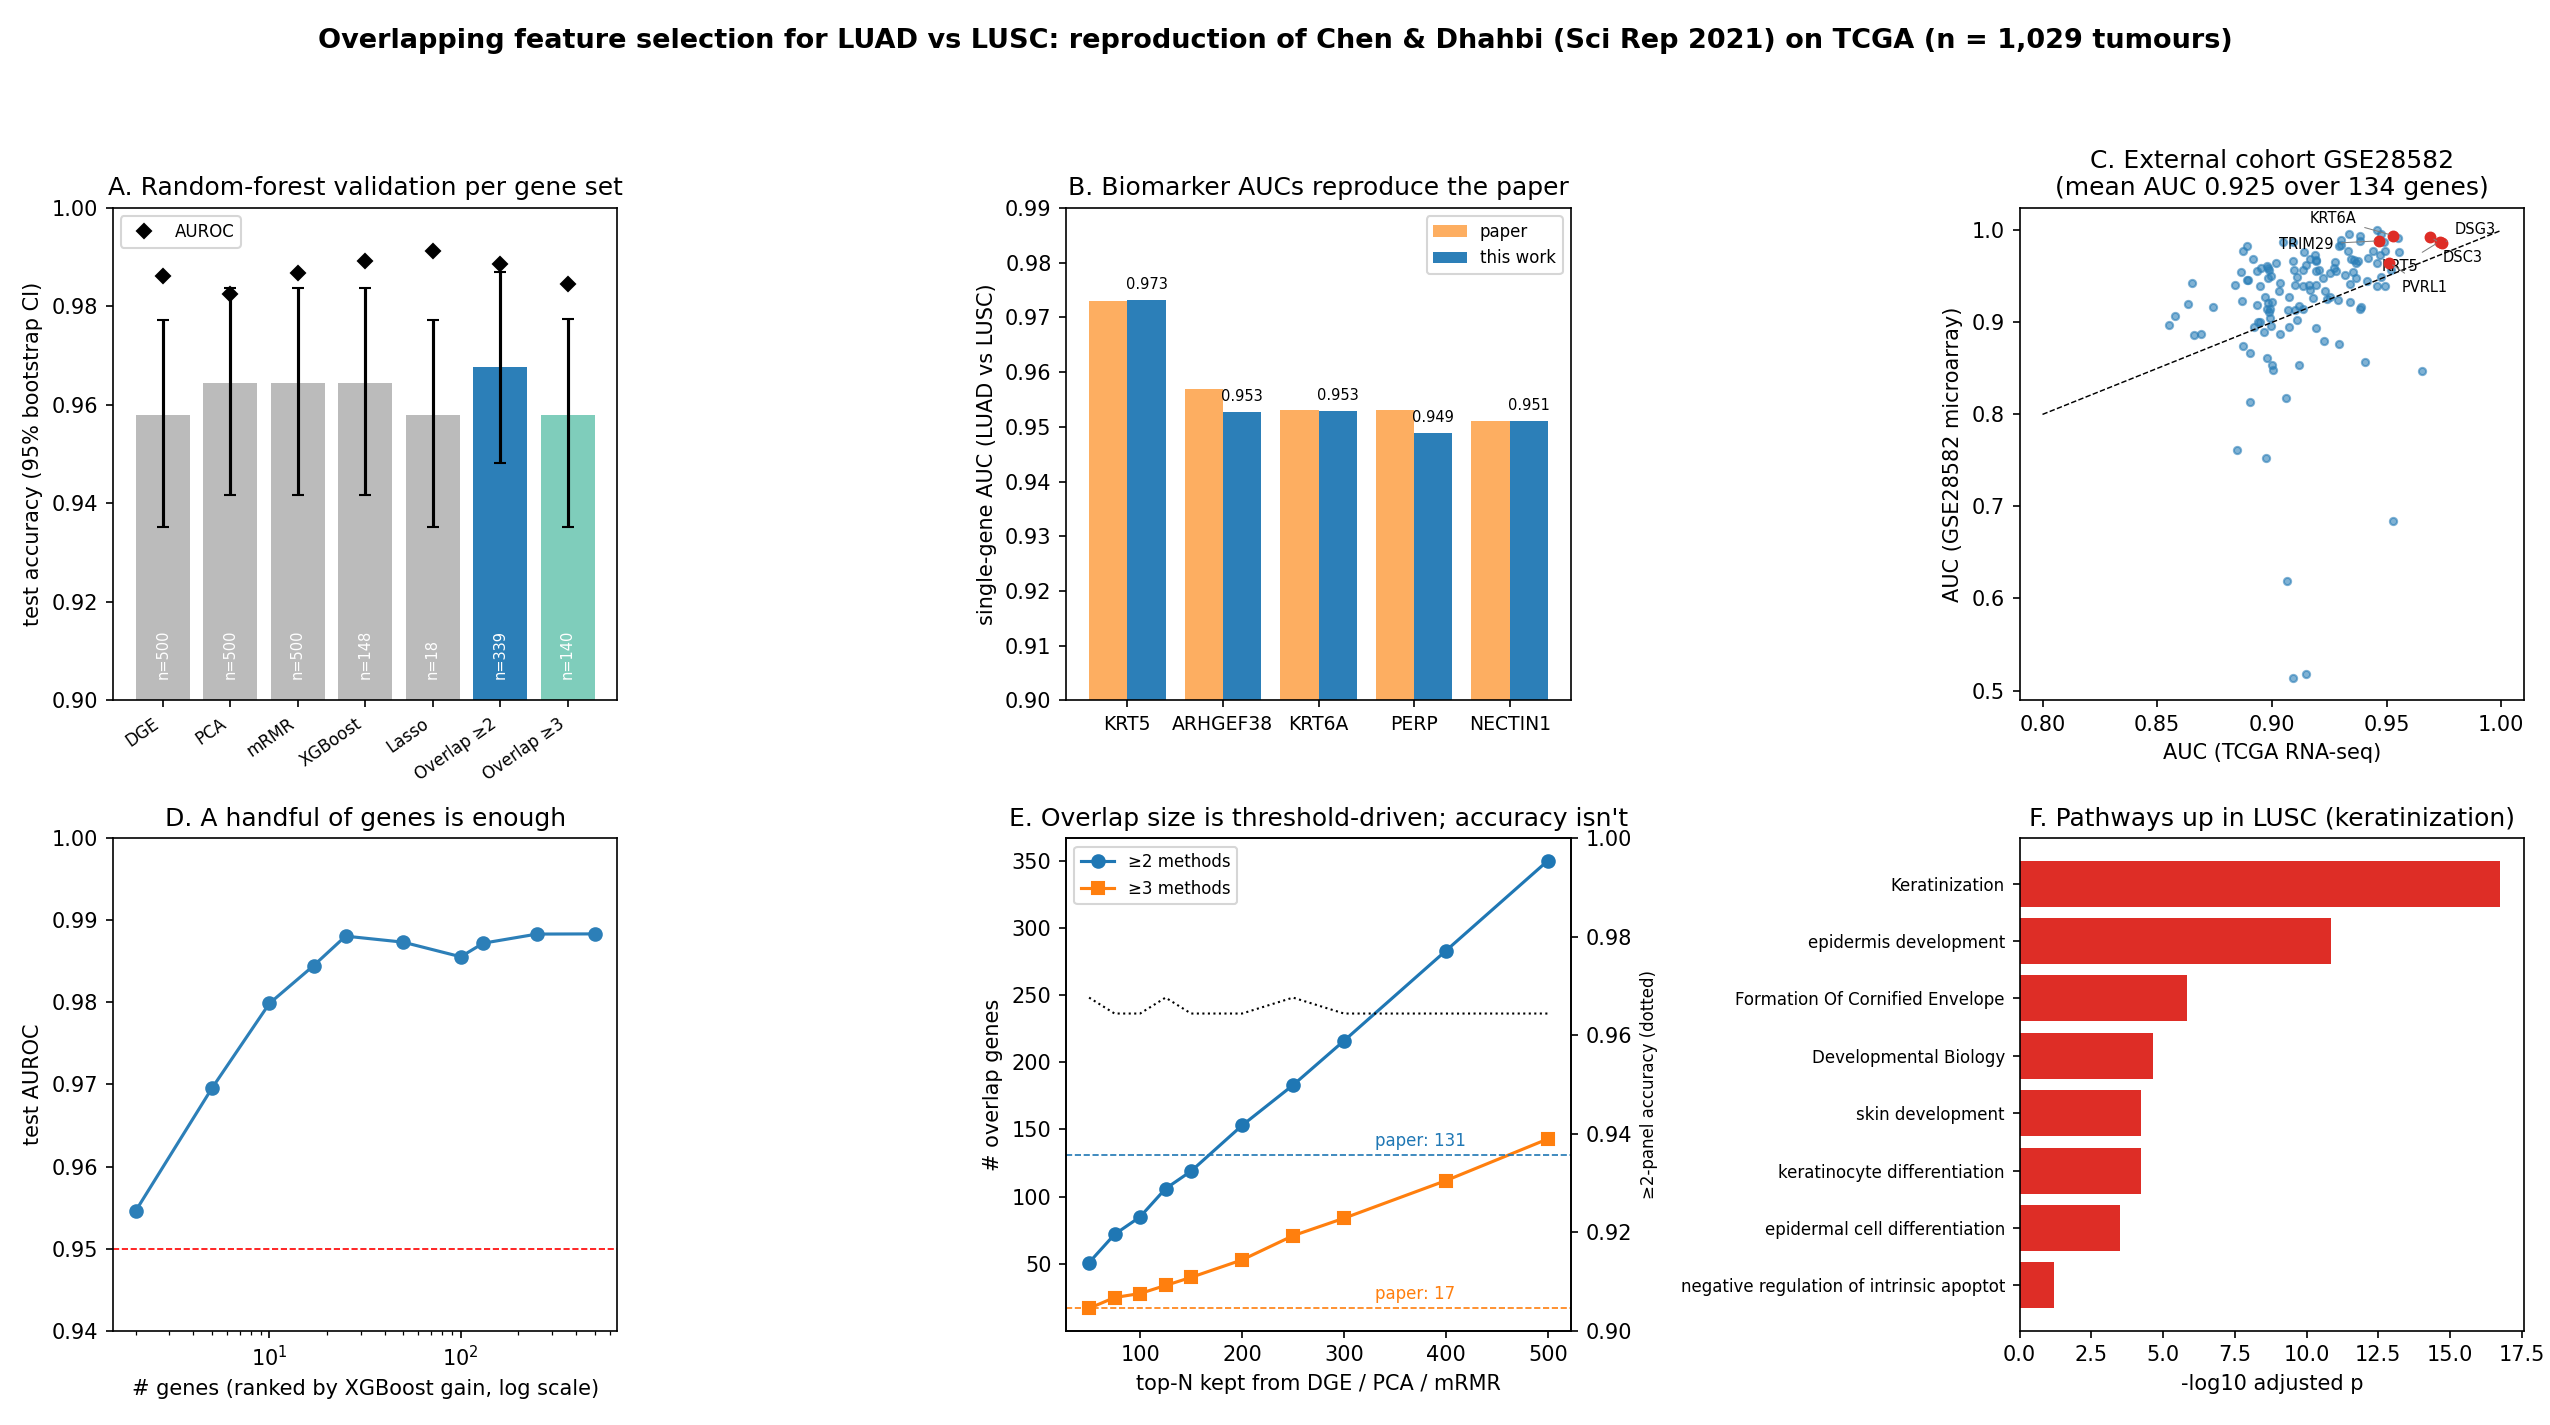

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path("..").resolve()
if not (ROOT / "results").exists():      # also works when run from the repo root
    ROOT = Path.cwd()
TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.precision", 3)
display(Image(filename=str(FIG / "summary_figure.png"), width=1000))

## 1. Five selectors and their overlap

Each method ran on the same patient-level training split:
- **DGE**: Welch t-test with FDR, top 500 genes
- **PCA**: top 500 genes by PC1 loading
- **mRMR**: 500 genes that are relevant but not redundant
- **XGBoost**: top 148 genes by gain
- **L1 logistic regression**: 1-SE rule

Genes picked by two or more methods form the classification panel.

In [2]:
sets = json.load(open(TAB / "feature_sets.json"))
sizes = pd.Series({k: len(v) for k, v in sets.items()}).rename(
    {"overlap131": "overlap (>=2 methods)", "overlap17": "overlap (>=3 methods)"})
membership = pd.read_csv(TAB / "overlap_membership.csv", index_col=0)
print("Genes selected per method:"); display(sizes.to_frame("n genes"))
print("How many methods picked each gene:")
display(membership["n_methods"].value_counts().sort_index().to_frame("n genes"))
print("Picked by all five methods:", ", ".join(sorted(membership.index[membership.n_methods == 5])))

Genes selected per method:


,n genes
DGE,500
PCA,500
mRMR,500
XGBoost,148
Lasso,18
overlap (>=2 methods),339
overlap (>=3 methods),140


How many methods picked each gene:


,n genes
n_methods,
1,815
2,199
3,113
4,21
5,6


Picked by all five methods: BCL2L15, DDAH1, DSC3, DSG3, KRT5, SIAH2


## 2. Does the overlap classify well?

Each gene set is scored by a grid-tuned random forest on held-out patients. LUAD is the positive class, and the confidence intervals come from 10,000 bootstrap resamples.

In [3]:
m = pd.read_csv(TAB / "classification_metrics.csv")
m["method"] = m["method"].replace({"overlap131": "overlap >=2", "overlap17": "overlap >=3"})
cols = ["method", "n_genes", "accuracy", "acc_lo", "acc_hi", "sensitivity", "specificity", "f_measure", "auroc"]
display(m[cols].set_index("method"))
best = m.loc[m.accuracy.idxmax()]
print(f"Best: {best.method} ({best.n_genes} genes), accuracy {best.accuracy:.3f}, AUROC {best.auroc:.3f}")

,n_genes,accuracy,acc_lo,acc_hi,sensitivity,specificity,f_measure,auroc
method,,,,,,,,
DGE,500,0.958,0.935,0.977,0.987,0.927,0.960,0.986
PCA,500,0.964,0.942,0.984,0.994,0.933,0.966,0.982
mRMR,500,0.964,0.942,0.984,1.000,0.927,0.967,0.987
XGBoost,148,0.964,0.942,0.984,1.000,0.927,0.967,0.989
Lasso,18,0.958,0.935,0.977,0.975,0.940,0.960,0.991
overlap >=2,339,0.968,0.948,0.987,1.000,0.933,0.970,0.989
overlap >=3,140,0.958,0.935,0.977,0.994,0.920,0.960,0.985


Best: overlap >=2 (339 genes), accuracy 0.968, AUROC 0.989


## 3. Biomarkers, and do they transfer to another platform?

Each gene is scored alone: its AUC for separating LUAD from LUSC. The same genes are then re-scored on the external microarray cohort, the strongest check that the signal isn't specific to TCGA.

In [4]:
tcga = pd.read_csv(TAB / "biomarker_auc_tcga.csv", index_col=0)
ext = pd.read_csv(TAB / "biomarker_auc_external.csv", index_col=0)
paper = {"KRT5": 0.973, "ARHGEF38": 0.957, "KRT6A": 0.953, "PERP": 0.953, "PVRL1": 0.951}
vs = pd.DataFrame({"AUC (paper)": paper, "AUC (this work)": tcga.loc[list(paper), "auc"]})
vs.index = [g if g != "PVRL1" else "NECTIN1 (PVRL1)" for g in vs.index]
display(vs)
top = tcga.join(ext, how="left").sort_values("auc", ascending=False).head(10)
top.columns = ["AUC TCGA", "logFC (LUSC vs LUAD)", "AUC GSE28582"]
display(top)
print(f"External cohort: mean AUC {ext.auc_external.mean():.3f} over {len(ext)} genes")

,AUC (paper),AUC (this work)
KRT5,0.973,0.973
ARHGEF38,0.957,0.953
KRT6A,0.953,0.953
PERP,0.953,0.949
NECTIN1 (PVRL1),0.951,0.951


,AUC TCGA,logFC (LUSC vs LUAD),AUC GSE28582
gene,,,
DSG3,0.974,7.035,0.986
KRT5,0.973,9.029,0.988
DSC3,0.969,6.445,0.993
CERS3,0.965,3.862,0.847
SERPINB13,0.955,4.852,0.976
KRT6B,0.955,5.933,0.992
KRT6A,0.953,7.749,0.994
ARHGEF38,0.953,-2.571,0.684
BNC1,0.952,4.271,0.956


External cohort: mean AUC 0.925 over 134 genes


## 4. What biology separates the subtypes?

This is over-representation analysis on the overlap genes, split by the direction of change.

In [5]:
up = pd.read_csv(TAB / "enrichment_up.csv")
show = ["Term", "library", "Overlap", "Adjusted P-value"]
print("Up in LUSC:"); display(up[show].head(8).reset_index(drop=True))
down = pd.read_csv(TAB / "enrichment_down.csv")
print("Up in LUAD:"); display(down[show].head(5).reset_index(drop=True))

Up in LUSC:


,Term,library,Overlap,Adjusted P-value
0,Keratinization R-HSA-6805567,Reactome_2022,17/50,1.790e-17
1,epidermis development (GO:0008544),GO_Biological_Process_2021,14/57,1.390e-11
2,Formation Of Cornified Envelope R-HSA-6809371,Reactome_2022,8/31,1.426e-06
3,Developmental Biology R-HSA-1266738,Reactome_2022,29/744,2.236e-05
4,skin development (GO:0043588),GO_Biological_Process_2021,9/64,6.057e-05
5,keratinocyte differentiation (GO:0030216),GO_Biological_Process_2021,7/32,6.057e-05
6,epidermal cell differentiation (GO:0009913),GO_Biological_Process_2021,7/42,3.265e-04
7,negative regulation of intrinsic apoptotic sig...,GO_Biological_Process_2021,4/24,6.211e-02


Up in LUAD:


,Term,library,Overlap,Adjusted P-value
0,negative regulation of small GTPase mediated s...,GO_Biological_Process_2021,3/20,0.118
1,"substrate-dependent cell migration, cell exten...",GO_Biological_Process_2021,2/5,0.118
2,regulation of transport (GO:0051049),GO_Biological_Process_2021,4/31,0.118
3,positive regulation of blood-brain barrier per...,GO_Biological_Process_2021,2/5,0.118
4,O-glycan processing (GO:0016266),GO_Biological_Process_2021,4/46,0.118


## 5. Extensions beyond the paper

In [6]:
print("Three-class LUAD / LUSC / Normal:")
display(pd.read_csv(TAB / "threeclass_metrics.csv").set_index("features")
        .rename(index={"overlap131": "overlap >=2 panel", "all_genes": "all genes"}))
print("How many genes are needed? (test AUROC vs panel size)")
display(pd.read_csv(TAB / "ablation_auc.csv").set_index("n_genes").T)

Three-class LUAD / LUSC / Normal:


,n_genes,accuracy,macro_f1,macro_auroc
features,,,,
overlap >=2 panel,339,0.959,0.957,0.992
all genes,15686,0.962,0.964,0.992


How many genes are needed? (test AUROC vs panel size)


n_genes,2,5,10,17,25,50,100,131,250,500
auroc,0.955,0.97,0.98,0.984,0.988,0.987,0.986,0.987,0.988,0.988


In [7]:
surv = pd.read_csv(TAB / "survival_biomarkers.csv")
print(f"Prognostic gene/histology pairs (log-rank p < 0.05): {(surv.logrank_p < 0.05).sum()} of {len(surv)}")
display(surv[surv.gene.isin(["KRT6A", "KRT17", "TRIM29", "PERP"]) & (surv.histology == "LUAD")]
        [["gene", "histology", "logrank_p", "cox_HR", "direction"]].reset_index(drop=True))
print("Stable, high-AUC candidates the paper doesn't highlight:")
display(pd.read_csv(TAB / "novel_candidates.csv", index_col=0).head(10))

Prognostic gene/histology pairs (log-rank p < 0.05): 63 of 280


,gene,histology,logrank_p,cox_HR,direction
0,PERP,LUAD,2.080e-04,1.356,high=worse
1,KRT6A,LUAD,2.771e-03,1.135,high=worse
2,KRT17,LUAD,1.552e-02,1.098,high=worse
3,TRIM29,LUAD,7.489e-02,1.116,high=worse


Stable, high-AUC candidates the paper doesn't highlight:


,auc,stability
DSG3,0.974,1.000
CERS3,0.965,1.000
SERPINB13,0.955,0.867
KRT6B,0.955,0.433
KRT6C,0.953,0.833
BNC1,0.952,0.600
S1PR5,0.949,0.800
MIR205HG,0.949,0.800
DDAH1,0.948,1.000
ATP1B3,0.947,0.600


## 6. How much do the paper's thresholds matter?

The paper reports 131 and 17 overlap genes, but doesn't fully specify its selector thresholds. Here, the number of genes taken from each ranked selector is varied.

,overlap_ge2,overlap_ge3,acc_ge2,auroc_ge2
top_N,,,,
50,51,17,0.968,0.987
75,72,25,0.964,0.986
100,85,28,0.964,0.985
125,106,34,0.968,0.986
150,119,40,0.964,0.985
200,153,53,0.964,0.986
250,183,71,0.968,0.986
300,216,84,0.964,0.986
400,283,112,0.964,0.987


Overlap size tracks the threshold; accuracy barely moves.


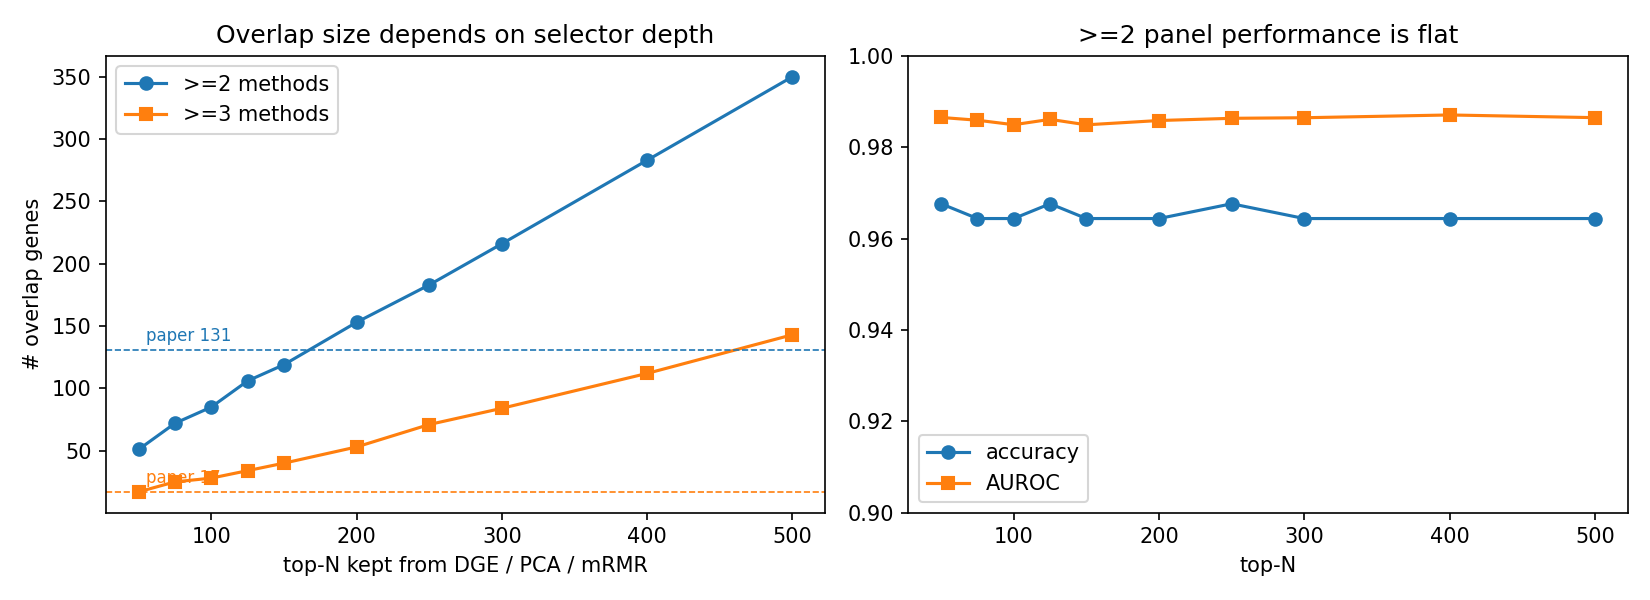

In [8]:
sv = pd.read_csv(TAB / "sensitivity_topN.csv").set_index("top_N")
display(sv[["overlap_ge2", "overlap_ge3", "acc_ge2", "auroc_ge2"]])
print("Overlap size tracks the threshold; accuracy barely moves.")
display(Image(filename=str(FIG / "sensitivity_overlap.png"), width=850))

## Where to go next

- `docs/REPORT.md`: full results and interpretation, including every deviation from the paper
- `docs/MODELS.md`: each model's settings and rationale, plus a leakage audit
- `docs/BLOG.md`: a plain-language write-up
- `src/`: the pipeline, steps `00` to `07`